In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_excel("online_retail_II.xlsx")

In [3]:
df
#Basic Check
df.shape
df.head
df.columns


Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')

In [4]:
#missing Value
df.isnull().sum()

Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

In [5]:
#duplicates value
df.duplicated().sum()
df[df.duplicated()].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [6]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [7]:
df['Description'] = df['Description'].fillna('Unknown')

In [8]:
df.isnull().sum()

Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107833
Country             0
dtype: int64

In [9]:
df = df.dropna(subset=['Customer ID'])

In [10]:
df.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

In [11]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [12]:
df['InvoiceDate'].dtype

dtype('<M8[us]')

In [13]:
df['TotalSales'] = df['Quantity'] * df['Price']

In [14]:
df[['Quantity', 'Price' , 'TotalSales']] .head()

,Quantity,Price,TotalSales
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


In [15]:
df[df['Quantity'] < 0].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalSales
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,-35.4
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia,-9.9
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia,-17.0
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia,-12.6
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,-35.4


In [16]:
(df['Quantity'] < 0).sum()

np.int64(9816)

In [17]:
df[df['Quantity'] < 0][['Invoice', 'Quantity', 'Price', 'TotalSales']].head(10)

,Invoice,Quantity,Price,TotalSales
178,C489449,-12,2.95,-35.40
179,C489449,-6,1.65,-9.90
180,C489449,-4,4.25,-17.00
181,C489449,-6,2.10,-12.60
182,C489449,-12,2.95,-35.40
183,C489449,-12,1.25,-15.00
184,C489449,-12,1.25,-15.00
185,C489449,-24,0.85,-20.40
186,C489449,-12,2.95,-35.40
196,C489459,-3,4.25,-12.75


In [18]:
df.dtypes


Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
TotalSales            float64
dtype: object

In [19]:
df.describe


<bound method NDFrame.describe of        Invoice StockCode                          Description  Quantity  \
0       489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1       489434    79323P                   PINK CHERRY LIGHTS        12   
2       489434    79323W                  WHITE CHERRY LIGHTS        12   
3       489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4       489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   
...        ...       ...                                  ...       ...   
525456  538171     22271                 FELTCRAFT DOLL ROSIE         2   
525457  538171     22750         FELTCRAFT PRINCESS LOLA DOLL         1   
525458  538171     22751       FELTCRAFT PRINCESS OLIVIA DOLL         1   
525459  538171     20970   PINK FLORAL FELTCRAFT SHOULDER BAG         2   
525460  538171     21931               JUMBO STORAGE BAG SUKI         2   

               InvoiceDate  Price  Customer ID         Country  T

In [20]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID,TotalSales
count,410763.000000,410763,410763.000000,410763.000000,410763.000000
mean,12.923735,2010-06-30 19:56:14.853674,3.908358,15353.621857,20.242465
min,-9360.000000,2009-12-01 07:45:00,0.000000,12346.000000,-25111.090000
25%,2.000000,2010-03-26 09:46:00,1.250000,13979.000000,4.500000
50%,5.000000,2010-07-08 15:09:00,1.950000,15311.000000,11.800000
75%,12.000000,2010-10-14 12:32:00,3.750000,16797.000000,19.500000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000,15818.400000
std,102.039550,NaN,71.714794,1681.657665,100.710825


In [21]:
df[["Quantity" , "Price" , "TotalSales"]].describe()

,Quantity,Price,TotalSales
count,410763.000000,410763.000000,410763.000000
mean,12.923735,3.908358,20.242465
std,102.039550,71.714794,100.710825
min,-9360.000000,0.000000,-25111.090000
25%,2.000000,1.250000,4.500000
50%,5.000000,1.950000,11.800000
75%,12.000000,3.750000,19.500000
max,19152.000000,25111.090000,15818.400000


<Axes: >

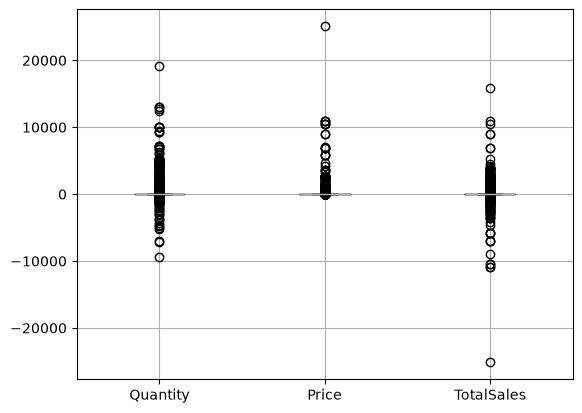

In [22]:
df[["Quantity" , "Price" , "TotalSales"]].boxplot()

In [23]:
(df["Quantity"] < 0).sum()

np.int64(9816)

In [24]:
df[df["Quantity"] < 0][["Quantity" , "Price", "TotalSales"]].head(10)

,Quantity,Price,TotalSales
178,-12,2.95,-35.40
179,-6,1.65,-9.90
180,-4,4.25,-17.00
181,-6,2.10,-12.60
182,-12,2.95,-35.40
183,-12,1.25,-15.00
184,-12,1.25,-15.00
185,-24,0.85,-20.40
186,-12,2.95,-35.40
196,-3,4.25,-12.75


In [25]:
df = df[df["Quantity"] > 0]

In [26]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalSales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.00
...,...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom,5.90
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,3.75
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,3.75
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,7.50


In [27]:
df.shape

(400947, 9)

In [28]:
(df["Price"] <= 0).sum()

np.int64(31)

In [29]:
df[df["Price"] <= 0][["Quantity" , "Price" , "TotalSales"]]

,Quantity,Price,TotalSales
4674,12,0.0,0.0
6781,2,0.0,0.0
16107,1,0.0,0.0
18738,1,0.0,0.0
18739,12,0.0,0.0
32916,8,0.0,0.0
40101,12,0.0,0.0
47126,24,0.0,0.0
48342,10,0.0,0.0
57619,12,0.0,0.0


In [30]:
df = df[df["Price"] > 0]

In [31]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalSales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.00
...,...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.0,United Kingdom,5.90
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,3.75
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,3.75
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.0,United Kingdom,7.50


In [32]:
(df["Price"] <= 0).sum()

np.int64(0)

In [33]:
df.shape

(400916, 9)

In [34]:
df["TotalSales"].describe()

count    400916.000000
mean         21.945330
std          77.758075
min           0.001000
25%           5.000000
50%          12.500000
75%          19.500000
max       15818.400000
Name: TotalSales, dtype: float64

In [35]:
df["TotalSales"].isnull().sum()

np.int64(0)

In [36]:
df["Customer ID"].dtype

dtype('float64')

In [37]:
df["Customer ID"].isnull().sum()

np.int64(0)

In [38]:
df["Customer ID"].head(10)

0    13085.0
1    13085.0
2    13085.0
3    13085.0
4    13085.0
5    13085.0
6    13085.0
7    13085.0
8    13085.0
9    13085.0
Name: Customer ID, dtype: float64

In [39]:
df["Customer ID"] = df["Customer ID"].astype(int)

In [40]:
df["Customer ID"].dtype

dtype('int64')

In [41]:
df.duplicated().sum()

np.int64(0)

In [42]:
df.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
TotalSales     0
dtype: int64

In [43]:
df.shape

(400916, 9)

In [44]:
df["InvoiceMonth"] = df["InvoiceDate"].dt.to_period("M")

In [45]:
df[["InvoiceDate" , "InvoiceMonth"]].head()

,InvoiceDate,InvoiceMonth
0,2009-12-01 07:45:00,2009-12
1,2009-12-01 07:45:00,2009-12
2,2009-12-01 07:45:00,2009-12
3,2009-12-01 07:45:00,2009-12
4,2009-12-01 07:45:00,2009-12


In [46]:
monthly_sales = df.groupby("InvoiceMonth")["TotalSales"].sum().reset_index()

monthly_sales.head()

,InvoiceMonth,TotalSales
0,2009-12,683504.010
1,2010-01,555802.672
2,2010-02,504558.956
3,2010-03,696978.471
4,2010-04,591982.002


In [47]:
monthly_demand = df.groupby("InvoiceMonth")["Quantity"].sum().reset_index()

monthly_demand.head()

,InvoiceMonth,Quantity
0,2009-12,398660
1,2010-01,370082
2,2010-02,371861
3,2010-03,502100
4,2010-04,350587


In [48]:
monthly_data = pd.merge(
    monthly_sales,
    monthly_demand,
    on= "InvoiceMonth"
)

monthly_data.head()

,InvoiceMonth,TotalSales,Quantity
0,2009-12,683504.010,398660
1,2010-01,555802.672,370082
2,2010-02,504558.956,371861
3,2010-03,696978.471,502100
4,2010-04,591982.002,350587


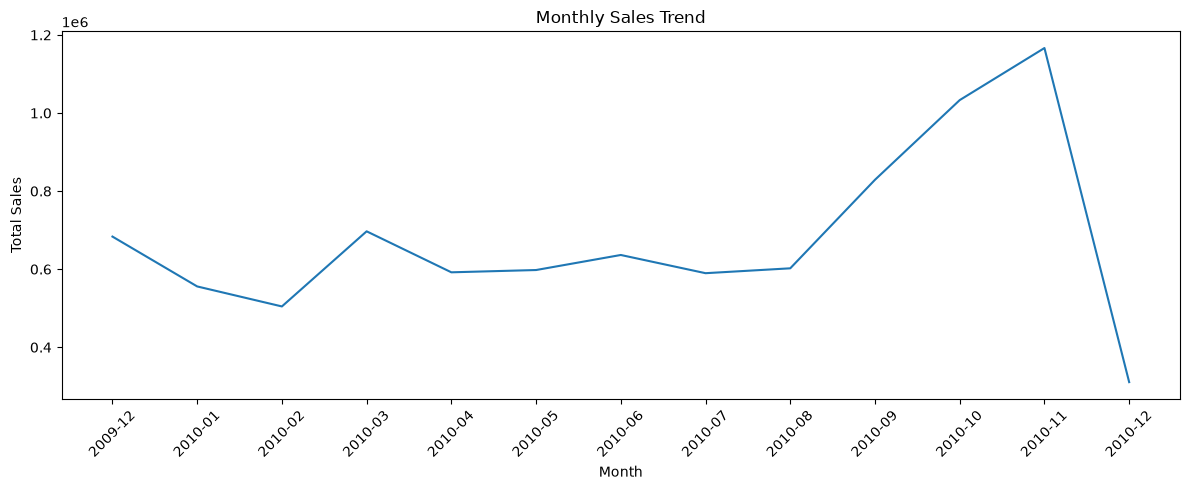

In [49]:
# VISUALIZATION

import matplotlib.pyplot as plt
plt.figure(figsize =(12,5))
plt.plot(monthly_data["InvoiceMonth"].astype(str)
,monthly_data["TotalSales"])
plt.xticks(rotation = 45)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.title("Monthly Sales Trend")
plt.tight_layout()
plt.show()

In [50]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country', 'TotalSales', 'InvoiceMonth'],
      dtype='str')

In [51]:
df["Customer ID"].isna().sum()

np.int64(0)

In [52]:
rfm_data = df[["Customer ID", "Invoice", "InvoiceDate", "TotalSales"]].copy()

rfm_data.head()


,Customer ID,Invoice,InvoiceDate,TotalSales
0,13085,489434,2009-12-01 07:45:00,83.4
1,13085,489434,2009-12-01 07:45:00,81.0
2,13085,489434,2009-12-01 07:45:00,81.0
3,13085,489434,2009-12-01 07:45:00,100.8
4,13085,489434,2009-12-01 07:45:00,30.0


In [53]:
reference_date = rfm_data["InvoiceDate"].max() + pd.Timedelta(days=1)

reference_date

Timestamp('2010-12-10 20:01:00')

In [54]:
rfm = rfm_data.groupby("Customer ID").agg(Recency=("InvoiceDate" , lambda x:(reference_date - x.max()).days))

rfm.head()

,Recency
Customer ID,
12346,165
12347,3
12348,74
12349,43
12351,11


In [55]:
rfm["Frequency"] = rfm_data.groupby("Customer ID")["Invoice"].nunique()

rfm.head()

,Recency,Frequency
Customer ID,,
12346,165,11
12347,3,2
12348,74,1
12349,43,3
12351,11,1


In [56]:
rfm["Monetary"]= rfm_data.groupby("Customer ID")["TotalSales"].sum()


rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346,165,11,372.86
12347,3,2,1323.32
12348,74,1,222.16
12349,43,3,2671.14
12351,11,1,300.93


In [57]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
Customer ID,,,,,,
12346,165,11,372.86,2,5,2
12347,3,2,1323.32,5,2,4
12348,74,1,222.16,2,1,1
12349,43,3,2671.14,3,3,5
12351,11,1,300.93,5,1,2


In [58]:
rfm["RFM_Score"] = (rfm["R_Score"].astype(int).astype(str) + rfm["F_Score"].astype(int).astype(str) + rfm["M_Score"].astype(int).astype(str))


rfm.head()
                    

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
Customer ID,,,,,,,
12346,165,11,372.86,2,5,2,252
12347,3,2,1323.32,5,2,4,524
12348,74,1,222.16,2,1,1,211
12349,43,3,2671.14,3,3,5,335
12351,11,1,300.93,5,1,2,512


In [59]:
rfm[["R_Score", "F_Score" , "M_Score"]].describe()

,R_Score,F_Score,M_Score
count,4312,4312,4312
unique,5,5,5
top,5,1,1
freq,906,863,863


In [60]:
def rfm_segment(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    elif row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Lost Customers"
    else:
        return "Others"

rfm["Segment"] = rfm.apply(rfm_segment, axis=1)

rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
Customer ID,,,,,,,,
12346,165,11,372.86,2,5,2,252,At Risk
12347,3,2,1323.32,5,2,4,524,Others
12348,74,1,222.16,2,1,1,211,Lost Customers
12349,43,3,2671.14,3,3,5,335,Loyal Customers
12351,11,1,300.93,5,1,2,512,Others


In [61]:
segment_counts = rfm["Segment"].value_counts()


segment_counts

Segment
Lost Customers     1015
Loyal Customers     973
Champions           926
Others              710
At Risk             688
Name: count, dtype: int64

In [62]:
segment_sales = rfm.groupby("Segment") ["Monetary"].sum().sort_values(ascending= False)

segment_sales

Segment
Champions          5712430.697
Loyal Customers    1306369.802
At Risk            1036709.791
Lost Customers      408503.374
Others              334220.080
Name: Monetary, dtype: float64

In [63]:
segment_revenue_pct = (segment_sales / segment_sales.sum() * 100).round(2)

segment_revenue_pct

Segment
Champions          64.93
Loyal Customers    14.85
At Risk            11.78
Lost Customers      4.64
Others              3.80
Name: Monetary, dtype: float64

In [64]:
from sklearn.preprocessing import StandardScaler

rfm_kmeans = rfm[["Recency" ,"Frequency" , "Monetary"]].copy()

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_kmeans)


rfm_scaled[:5]

array([[ 0.76229851,  0.80108727, -0.18713934],
       [-0.91040156, -0.3006029 , -0.08047459],
       [-0.17730462, -0.42301292, -0.20405155],
       [-0.4973892 , -0.17819288,  0.07078363],
       [-0.82779909, -0.42301292, -0.19521163]])

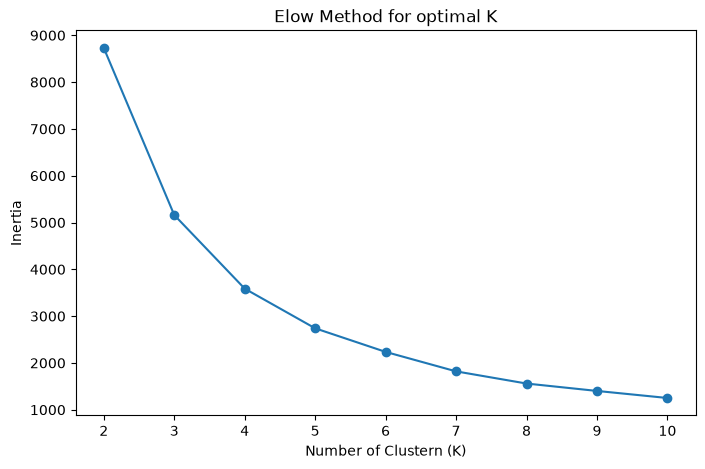

In [65]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
inertia = []

for k in range(2,11):
    kmeans = KMeans(n_clusters = k, random_state = 42, n_init = 10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize = (8,5))
plt.plot(range(2,11), inertia, marker = "o")
plt.xlabel("Number of Clustern (K)")
plt.ylabel("Inertia")
plt.title("Elow Method for optimal K")
plt.show()
    
    
                    

In [66]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5,random_state=42, n_init=10)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)


rfm.head
                

<bound method NDFrame.head of              Recency  Frequency  Monetary R_Score F_Score M_Score RFM_Score  \
Customer ID                                                                   
12346            165         11    372.86       2       5       2       252   
12347              3          2   1323.32       5       2       4       524   
12348             74          1    222.16       2       1       1       211   
12349             43          3   2671.14       3       3       5       335   
12351             11          1    300.93       5       1       2       512   
...              ...        ...       ...     ...     ...     ...       ...   
18283             18          6    619.37       4       5       3       453   
18284             67          1    461.68       3       2       2       322   
18285            296          1    427.00       1       2       2       122   
18286            112          2   1296.43       2       3       4       234   
18287             18  

In [67]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()

cluster_counts

Cluster
0     208
1    3053
2      10
3       3
4    1038
Name: count, dtype: int64

In [68]:
cluster_summary = rfm.groupby("Cluster")[["Recency", "Frequency" , "Monetary"]].mean()


cluster_summary

,Recency,Frequency,Monetary
Cluster,,,
0,16.774038,21.764423,12210.231168
1,44.697674,3.770390,1370.060919
2,3.700000,118.100000,66250.547000
3,6.000000,89.666667,264703.530000
4,243.860308,1.661850,596.429301


In [69]:
cluster_summary["Customer_Count"] = rfm.groupby("Cluster").size()

cluster_summary["Customer_Percentage"] = (
    cluster_summary["Customer_Count"] / len(rfm) * 100
)

cluster_summary

,Recency,Frequency,Monetary,Customer_Count,Customer_Percentage
Cluster,,,,,
0,16.774038,21.764423,12210.231168,208,4.823748
1,44.697674,3.770390,1370.060919,3053,70.802412
2,3.700000,118.100000,66250.547000,10,0.231911
3,6.000000,89.666667,264703.530000,3,0.069573
4,243.860308,1.661850,596.429301,1038,24.072356


In [70]:
from sklearn.metrics import silhouette_score

silhouette_avg = silhouette_score(rfm_scaled, rfm["Cluster"])

print("Silhouette Score:", silhouette_avg)

Silhouette Score: 0.6139631889762288


In [71]:
## Time-Series Data Preparation for forecasting 

daily_sales =df.groupby(df["InvoiceDate"].dt.date)["TotalSales"].sum().reset_index()

daily_sales.columns = ["Date" , "Sales"]


daily_sales["Date"] = pd.to_datetime(daily_sales["Date"])


daily_sales.head()



,Date,Sales
0,2009-12-01,43894.87
1,2009-12-02,52762.06
2,2009-12-03,67413.62
3,2009-12-04,33913.81
4,2009-12-05,9803.05


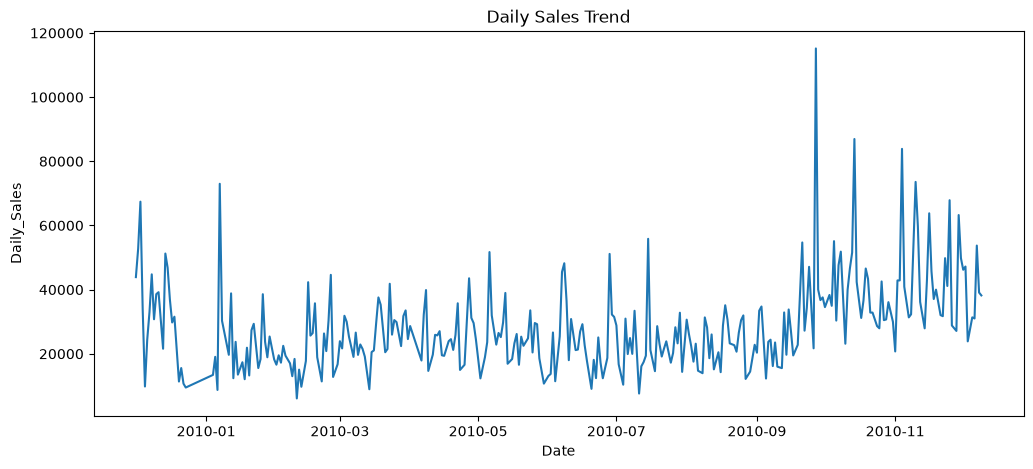

In [72]:
plt.figure(figsize=(12,5))

plt.plot(daily_sales["Date"], daily_sales["Sales"])

plt.xlabel("Date")
plt.ylabel("Daily_Sales")
plt.title("Daily Sales Trend")

plt.show()

In [73]:
daily_sales["Date"].diff().value_counts()

Date
1 days     252
2 days      52
12 days      1
5 days       1
Name: count, dtype: int64

In [74]:
daily_sales = daily_sales.set_index("Date")
daily_sales = daily_sales.asfreq("D" , fill_value = 0)
daily_sales = daily_sales.reset_index()

daily_sales.head()

,Date,Sales
0,2009-12-01,43894.87
1,2009-12-02,52762.06
2,2009-12-03,67413.62
3,2009-12-04,33913.81
4,2009-12-05,9803.05


In [75]:
daily_sales["Date"].diff().value_counts()


Date
1 days    373
Name: count, dtype: int64

In [76]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(daily_sales["Sales"])
print("ADF Statistic:", result[0])
print("p-value:" , result[1])

ADF Statistic: -2.5649768902848686
p-value: 0.10045400925889841


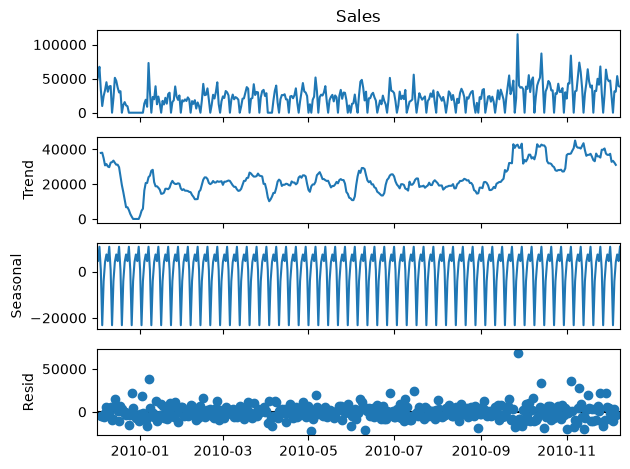

In [77]:
from statsmodels.tsa.seasonal import seasonal_decompose

daily_sales_decomposition = daily_sales.set_index("Date")

decomposition = seasonal_decompose(
    daily_sales_decomposition["Sales"],
    model="additive",
    period=7
)

decomposition.plot()

plt.show()

In [78]:
!pip install prophet

Defaulting to user installation because normal site-packages is not writeable


In [79]:
from prophet import Prophet
print("Prophet imported successfully")

Prophet imported successfully


In [80]:
prophet_df = daily_sales[["Date" , "Sales"]].copy()
prophet_df.columns = ["ds" , "y"]

prophet_df.head()

,ds,y
0,2009-12-01,43894.87
1,2009-12-02,52762.06
2,2009-12-03,67413.62
3,2009-12-04,33913.81
4,2009-12-05,9803.05


In [81]:
model = Prophet(
    daily_seasonality=False,
    weekly_seasonality=True,
    yearly_seasonality=True
)

print("Prophet model trained successfully")

Prophet model trained successfully


In [82]:
model.fit(prophet_df)
print("Prophet model fitted successfully")

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
12:19:46 - cmdstanpy - INFO - Chain [1] start processing
12:19:47 - cmdstanpy - INFO - Chain [1] done processing


Prophet model fitted successfully


In [83]:
future = model.make_future_dataframe(periods=30)

forecast = model.predict(future)

forecast[["ds" , "yhat" , "yhat_lower" , "yhat_upper"]].tail(30)

,ds,yhat,yhat_lower,yhat_upper
374,2010-12-10,25803.827054,12888.131810,39305.746962
375,2010-12-11,310.616028,-12624.721111,13505.015801
376,2010-12-12,17429.901469,3570.518965,30460.775448
377,2010-12-13,23678.791475,10686.230313,36599.950455
378,2010-12-14,25187.271240,13046.050157,37032.764916
379,2010-12-15,20373.028923,7974.652811,32575.035742
380,2010-12-16,24688.353773,11044.365623,37480.914200
381,2010-12-17,12402.644645,314.900882,25167.346632
382,2010-12-18,-13182.294945,-25794.601820,10.255131
383,2010-12-19,3999.324482,-9104.760491,16633.492932


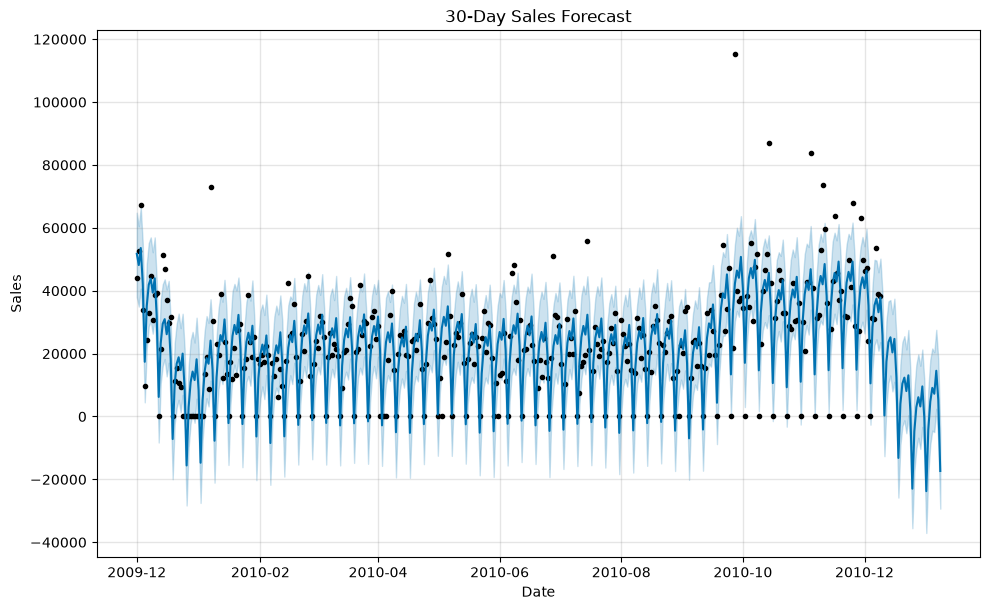

In [84]:
fig = model.plot(forecast)

plt.title("30-Day Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.show()

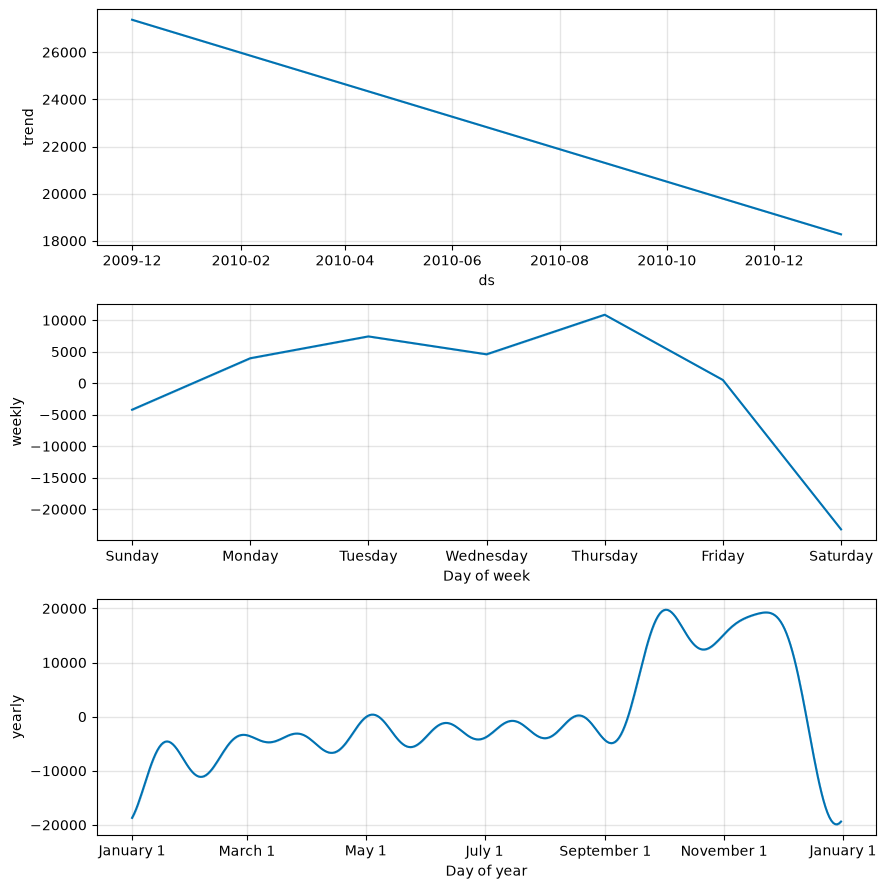

In [85]:
fig2 = model.plot_components(forecast)

plt.show()

In [86]:
import torch

print("PyTorch version:", torch.__version__)

print("CUDA available:",torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
CUDA available: False


In [87]:
import torch
import torch.nn as nn

print("PyTorch ready for LSMT")
print("Version:" , torch.__version__)

PyTorch ready for LSMT
Version: 2.14.1+cpu


In [88]:

daily_sales = (
    df.groupby(df["InvoiceDate"].dt.date)["TotalSales"]
    .sum()
    .reset_index()
)

daily_sales.columns = ["Date", "Sales"]

daily_sales["Date"] = pd.to_datetime(daily_sales["Date"])

daily_sales.head()

,Date,Sales
0,2009-12-01,43894.87
1,2009-12-02,52762.06
2,2009-12-03,67413.62
3,2009-12-04,33913.81
4,2009-12-05,9803.05


In [89]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

scaler = MinMaxScaler()

sales_scaled = scaler.fit_transform(
    daily_sales[["Sales"]]
)

print("Sales data scaled successfully")
print(sales_scaled[:5])

Sales data scaled successfully
[[0.34661806]
 [0.42790139]
 [0.5622086 ]
 [0.25512417]
 [0.03410682]]


In [90]:
sequence_length = 30

X = []
y = []

for i in range(sequence_length, len(sales_scaled)):
    X.append(sales_scaled[i-sequence_length:i])
    y.append(sales_scaled[i])

X = np.array(X)
y = np.array(y)

print("Sequences created successfully")
print("X shape:", X.shape)
print("y shape:", y.shape)

Sequences created successfully
X shape: (277, 30, 1)
y shape: (277, 1)


In [91]:
train_size = int(len(X) * 0.8)
X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

print("Training data:" ,  X_train.shape,y_train.shape)
print("Testing data:" , X_test.shape,y_test.shape)


Training data: (221, 30, 1) (221, 1)
Testing data: (56, 30, 1) (56, 1)


In [92]:
import torch
import torch.nn as nn

class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size,
            hidden_size,
            num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

model = LSTMModel()

print("LSTM model created successfully")

LSTM model created successfully


In [93]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

epochs = 100

for epoch in range(epochs):
    model.train()

    optimizer.zero_grad()

    output = model(X_train_tensor)
    loss = criterion(output, y_train_tensor)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.6f}")

Epoch [10/100], Loss: 0.012307
Epoch [20/100], Loss: 0.010240
Epoch [30/100], Loss: 0.010335
Epoch [40/100], Loss: 0.010236
Epoch [50/100], Loss: 0.010153
Epoch [60/100], Loss: 0.010143
Epoch [70/100], Loss: 0.010121
Epoch [80/100], Loss: 0.010091
Epoch [90/100], Loss: 0.010052
Epoch [100/100], Loss: 0.009995


In [94]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

model.eval()

with torch.no_grad():
    predictions = model(torch.tensor(X_test, dtype=torch.float32))

predictions = predictions.numpy()

# Convert scaled values back to original sales values


predicted_sales = scaler.inverse_transform(predictions)
actual_sales = scaler.inverse_transform(y_test)

mae = mean_absolute_error(actual_sales, predicted_sales)
rmse = np.sqrt(mean_squared_error(actual_sales, predicted_sales))

print("LSTM Model Evaluation")
print("MAE:", mae)
print("RMSE:", rmse)

LSTM Model Evaluation
MAE: 15800.024900390626
RMSE: 20884.926606966736


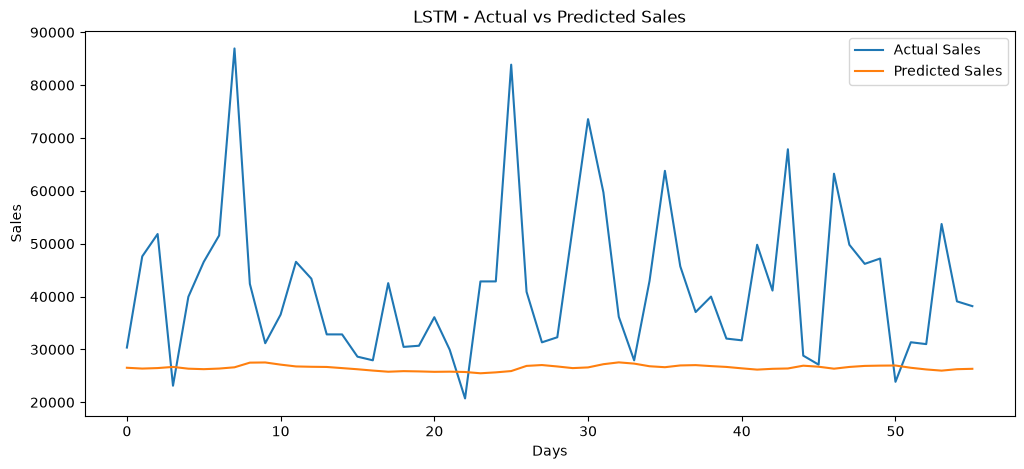

In [95]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(actual_sales, label="Actual Sales")
plt.plot(predicted_sales, label="Predicted Sales")

plt.xlabel("Days")
plt.ylabel("Sales")
plt.title("LSTM - Actual vs Predicted Sales")
plt.legend()
plt.show()

In [96]:
%pip install mlflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [97]:
import mlflow

print("MLflow version:", mlflow.__version__)
print("MLflow is ready")


MLflow version: 3.16.1
MLflow is ready


In [98]:
import mlflow

mlflow.set_experiment("RetailPulse_LSTM_Forecasting")

print("MLflow experiment created successfully")

MLflow experiment created successfully


In [99]:
with mlflow.start_run():

    mlflow.log_param("sequence_length", 30)
    mlflow.log_param("hidden_size", 64)
    mlflow.log_param("num_layers", 2)
    mlflow.log_param("epochs", 100)
    mlflow.log_param("learning_rate", 0.001)

    print("LSTM parameters logged successfully")

LSTM parameters logged successfully


In [100]:
with mlflow.start_run():

    mlflow.log_metric("MAE", mae)
    mlflow.log_metric("RMSE", rmse)

    print("LSTM metrics logged successfully")

LSTM metrics logged successfully


In [101]:
import mlflow.pytorch

input_example = X_train[:1].astype(np.float32)

with mlflow.start_run():

    mlflow.pytorch.log_model(
        model,
        artifact_path="lstm_model",
        input_example=input_example
    )

    print("LSTM model logged successfully")

2026/10/13 12:20:16 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
C:\ProgramData\anaconda3\Lib\contextlib.py:148: UserWarning: The tensor attributes self.lstm._flat_weights[0], self.lstm._flat_weights[1], self.lstm._flat_weights[2], self.lstm._flat_weights[3], self.lstm._flat_weights[4], self.lstm._flat_weights[5], self.lstm._flat_weights[6], self.lstm._flat_weights[7] were assigned during export. Such attributes must be registered as buffers using the `register_buffer` API (https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_buffer).
  next(self.gen)
W1013 12:20:19.266000 9112 torch\_export\non_strict_utils.py:825] dimension inputs[0].shape[0] 0/1 specialized; Dim.AUTO was specified along with a sample input with hint = 1.


LSTM model logged successfully


In [102]:
print("Model logging step completed")

Model logging step completed


In [103]:
### final checkpoint

print("===== RetailPulse Week 1 Verification =====")

print("MLflow Version:", mlflow.__version__)
print("Experiment:", mlflow.get_experiment_by_name("RetailPulse_LSTM_Forecasting").name)

print("\nLSTM Parameters:")
print("Sequence Length:", 30)
print("Hidden Size:", 64)
print("Layers:", 2)
print("Epochs:", 100)
print("Learning Rate:", 0.001)

print("\nLSTM Metrics:")
print("MAE:", mae)
print("RMSE:", rmse)

print("\nWeek 1 Status: COMPLETED")


===== RetailPulse Week 1 Verification =====
MLflow Version: 3.16.1
Experiment: RetailPulse_LSTM_Forecasting

LSTM Parameters:
Sequence Length: 30
Hidden Size: 64
Layers: 2
Epochs: 100
Learning Rate: 0.001

LSTM Metrics:
MAE: 15800.024900390626
RMSE: 20884.926606966736

Week 1 Status: COMPLETED


In [104]:
print("Prophet forecast:", forecast.shape)
print("LSTM predictions:", predicted_sales.shape)
print("Actual sales:", actual_sales.shape)

Prophet forecast: (404, 19)
LSTM predictions: (56, 1)
Actual sales: (56, 1)


In [105]:
prophet_test = forecast.tail(56)[["ds", "yhat"]].copy()

prophet_predictions = prophet_test["yhat"].values.reshape(-1, 1)

print("Prophet test predictions:", prophet_predictions.shape)

Prophet test predictions: (56, 1)


In [106]:
ensemble_predictions = (
    0.5 * prophet_predictions +
    0.5 * predicted_sales
)

print("Hybrid forecast created successfully")
print("Ensemble shape:", ensemble_predictions.shape)
print("First 5 predictions:")
print(ensemble_predictions[:5])


Hybrid forecast created successfully
Ensemble shape: (56, 1)
First 5 predictions:
[[30177.44402833]
 [34239.54737697]
 [36069.98095682]
 [34803.73461502]
 [37818.81630708]]


In [107]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

hybrid_mae = mean_absolute_error(
    actual_sales,
    ensemble_predictions
)

hybrid_rmse = np.sqrt(
    mean_squared_error(
        actual_sales,
        ensemble_predictions
    )
)

print("Hybrid Forecast Evaluation")
print("MAE:", hybrid_mae)
print("RMSE:", hybrid_rmse)

Hybrid Forecast Evaluation
MAE: 20105.939152699248
RMSE: 25368.64896552483


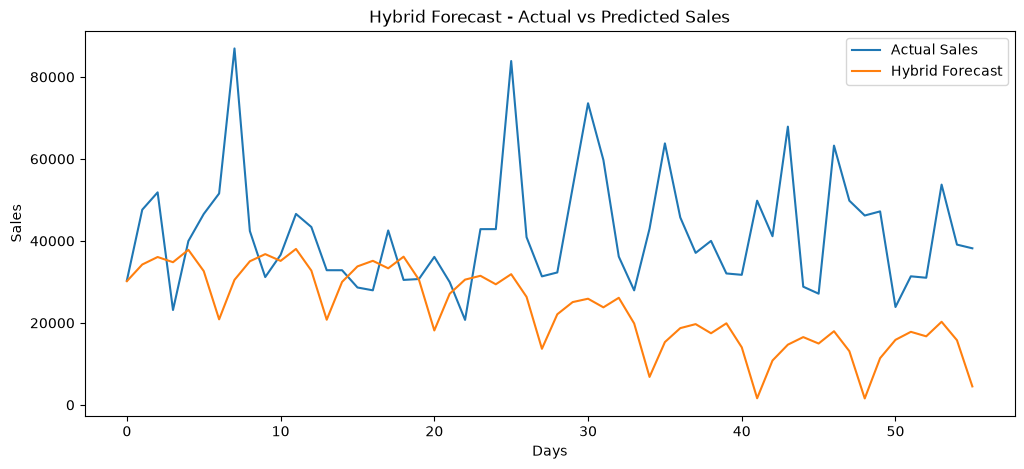

In [108]:
plt.figure(figsize=(12, 5))

plt.plot(actual_sales, label="Actual Sales")
plt.plot(ensemble_predictions, label="Hybrid Forecast")

plt.xlabel("Days")
plt.ylabel("Sales")
plt.title("Hybrid Forecast - Actual vs Predicted Sales")
plt.legend()
plt.show()


In [109]:
print(" Churn Prediction")
print("Customers:", rfm.shape[0])
print("RFM columns:", list(rfm.columns))

 Churn Prediction
Customers: 4312
RFM columns: ['Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Segment', 'Cluster']


In [110]:
rfm["Churn"] = (rfm["Recency"] >= 90).astype(int)

print("Churn target created successfully")
print(rfm["Churn"].value_counts())
print("\nChurn percentage:")
print(rfm["Churn"].value_counts(normalize=True) * 100)

Churn target created successfully
Churn
0    2877
1    1435
Name: count, dtype: int64

Churn percentage:
Churn
0    66.720779
1    33.279221
Name: proportion, dtype: float64


In [111]:
X = rfm[[
    "Recency",
    "Frequency",
    "Monetary",
    "R_Score",
    "F_Score",
    "M_Score"
]]

y = rfm["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())

Features shape: (4312, 6)
Target shape: (4312,)

Features:
['Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score']


In [112]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (3449, 6)
Testing data: (863, 6)
Training target: (3449,)
Testing target: (863,)


In [113]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [114]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

print("XGBoost churn model trained successfully")

XGBoost churn model trained successfully


In [115]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (3449, 6)
X_test shape: (863, 6)
y_train shape: (3449,)
y_test shape: (863,)


In [116]:
import joblib

joblib.dump(xgb_model, "retailpulse_churn_model.pkl")

print("Churn model saved successfully!")

Churn model saved successfully!


In [117]:
import os

print(os.path.abspath("retailpulse_churn_model.pkl"))
print(os.path.exists("retailpulse_churn_model.pkl"))

C:\Users\aanan\Desktop\RetailPulse\retailpulse_churn_model.pkl
True


In [118]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Prediction
y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
ROC-AUC: 1.0

Confusion Matrix:
[[576   0]
 [  0 287]]


In [119]:
%pip install shap

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [120]:
import shap

# Create SHAP explainer
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test)

print("SHAP analysis completed!")
print("SHAP values shape:", shap_values.shape)

SHAP analysis completed!
SHAP values shape: (863, 6)


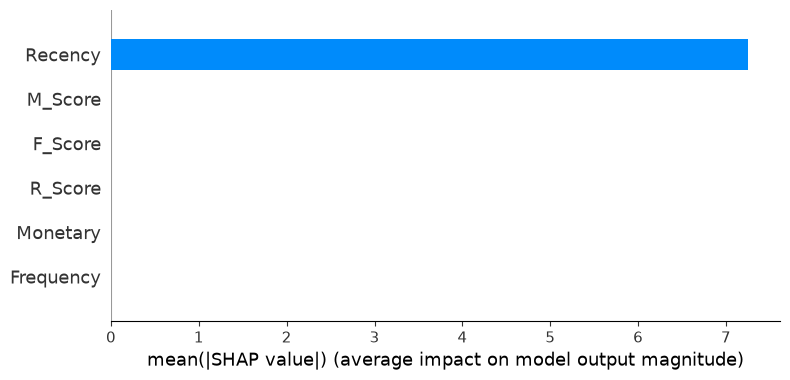

In [121]:
import matplotlib.pyplot as plt

shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)

In [122]:
# Day 10 - Inventory Optimization

inventory_forecast = forecast[["ds", "yhat"]].copy()

inventory_forecast.columns = ["Date", "Forecasted_Demand"]

# Negative demand ko zero karna
inventory_forecast["Forecasted_Demand"] = (
    inventory_forecast["Forecasted_Demand"].clip(lower=0)
)

print("Inventory forecast prepared!")
print(inventory_forecast.head())
print("\nShape:", inventory_forecast.shape)

Inventory forecast prepared!
        Date  Forecasted_Demand
0 2009-12-01       51761.711199
1 2009-12-02       48173.866993
2 2009-12-03       53584.054129
3 2009-12-04       42233.806485
4 2009-12-05       17398.980658

Shape: (404, 2)


In [123]:
# Calculate demand statistics
demand_mean = inventory_forecast["Forecasted_Demand"].mean()
demand_std = inventory_forecast["Forecasted_Demand"].std()

# Inventory parameters
lead_time = 7       # 7 days
safety_factor = 1.65

# Safety Stock
safety_stock = safety_factor * demand_std * (lead_time ** 0.5)

# Reorder Point
reorder_point = (demand_mean * lead_time) + safety_stock

print("Average Forecasted Demand:", demand_mean)
print("Demand Standard Deviation:", demand_std)
print("Safety Stock:", safety_stock)
print("Reorder Point:", reorder_point)

Average Forecasted Demand: 22835.233853022033
Demand Standard Deviation: 12739.872872107602
Safety Stock: 55615.78333438858
Reorder Point: 215462.4203055428


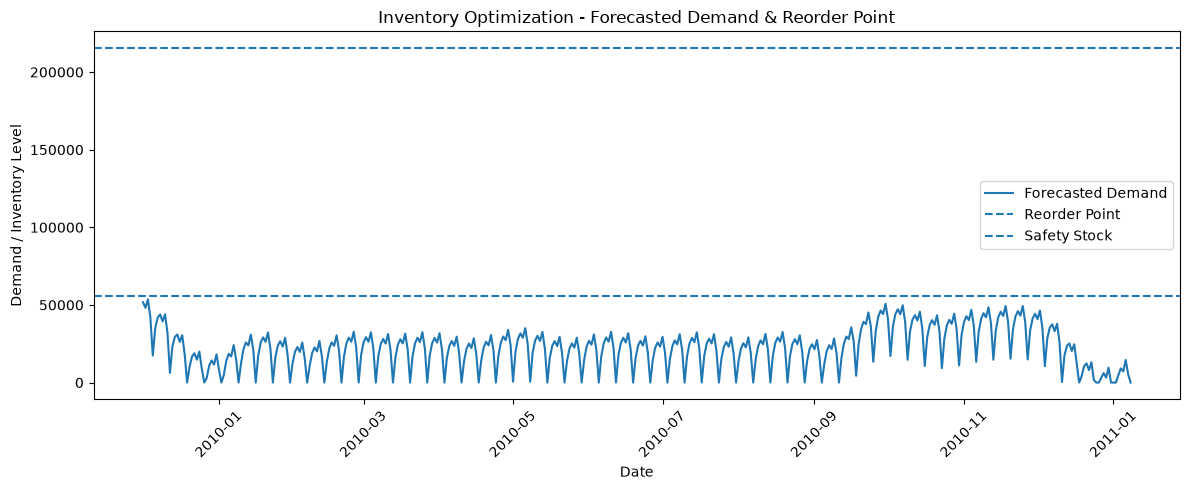

In [124]:
plt.figure(figsize=(12, 5))

plt.plot(
    inventory_forecast["Date"],
    inventory_forecast["Forecasted_Demand"],
    label="Forecasted Demand"
)

plt.axhline(
    reorder_point,
    linestyle="--",
    label="Reorder Point"
)

plt.axhline(
    safety_stock,
    linestyle="--",
    label="Safety Stock"
)

plt.xlabel("Date")
plt.ylabel("Demand / Inventory Level")
plt.title("Inventory Optimization - Forecasted Demand & Reorder Point")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [125]:
# Inventory recommendation

target_inventory = reorder_point + safety_stock

print("Inventory Optimization Summary")
print("--------------------------------")
print("Average Daily Demand:", round(demand_mean, 2))
print("Safety Stock:", round(safety_stock, 2))
print("Reorder Point:", round(reorder_point, 2))
print("Recommended Target Inventory:", round(target_inventory, 2))

Inventory Optimization Summary
--------------------------------
Average Daily Demand: 22835.23
Safety Stock: 55615.78
Reorder Point: 215462.42
Recommended Target Inventory: 271078.2


In [126]:
%pip install optuna

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [127]:
import optuna
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

def objective(trial):

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 200),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "random_state": 42,
        "eval_metric": "logloss"
    }

    model = XGBClassifier(**params)
    model.fit(X_train, y_train)

    y_prob = model.predict_proba(X_test)[:, 1]

    return roc_auc_score(y_test, y_prob)


study = optuna.create_study(direction="maximize")

study.optimize(objective, n_trials=20)

print("Best ROC-AUC:", study.best_value)
print("\nBest Parameters:")
print(study.best_params)

[I 2026-10-13 12:20:47,348] A new study created in memory with name: no-name-95420583-56a1-443f-91aa-6be29021bc92
[I 2026-10-13 12:20:47,609] Trial 0 finished with value: 0.9999999999999999 and parameters: {'n_estimators': 176, 'max_depth': 8, 'learning_rate': 0.22124295204086744, 'subsample': 0.6497469408169176, 'colsample_bytree': 0.9914106562629071}. Best is trial 0 with value: 0.9999999999999999.
[I 2026-10-13 12:20:47,747] Trial 1 finished with value: 1.0 and parameters: {'n_estimators': 82, 'max_depth': 3, 'learning_rate': 0.26107068638420283, 'subsample': 0.6149078108427393, 'colsample_bytree': 0.833252538458279}. Best is trial 1 with value: 1.0.
[I 2026-10-13 12:20:47,868] Trial 2 finished with value: 1.0 and parameters: {'n_estimators': 53, 'max_depth': 6, 'learning_rate': 0.08677102471036026, 'subsample': 0.7160450909503844, 'colsample_bytree': 0.6149090257253205}. Best is trial 1 with value: 1.0.
[I 2026-10-13 12:20:48,071] Trial 3 finished with value: 1.0 and parameters: {'

Best ROC-AUC: 1.0

Best Parameters:
{'n_estimators': 82, 'max_depth': 3, 'learning_rate': 0.26107068638420283, 'subsample': 0.6149078108427393, 'colsample_bytree': 0.833252538458279}


In [128]:
best_params = study.best_params

tuned_xgb_model = XGBClassifier(
    **best_params,
    random_state=42,
    eval_metric="logloss"
)

tuned_xgb_model.fit(X_train, y_train)

print("Tuned XGBoost model training completed!")



Tuned XGBoost model training completed!


Feature Importance:
Recency      0.710074
R_Score      0.236020
Frequency    0.046718
Monetary     0.005463
F_Score      0.001428
M_Score      0.000297
dtype: float32


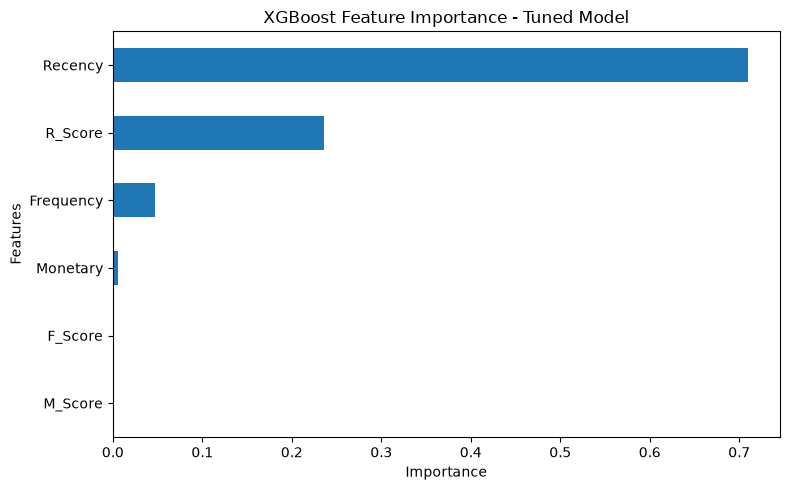

In [129]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    tuned_xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance)

plt.figure(figsize=(8, 5))
feature_importance.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("XGBoost Feature Importance - Tuned Model")
plt.tight_layout()
plt.show()

In [130]:
%pip install evidently

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [131]:
#  Drift Detection using Evidently AI

import pandas as pd
import evidently

# Reference and current datasets
reference_data = X_train.copy()
current_data = X_test.copy()

print("Evidently version:", evidently.__version__)
print("Reference data shape:", reference_data.shape)
print("Current data shape:", current_data.shape)
print("\nFeatures:")
print(list(reference_data.columns))

Evidently version: 0.7.23
Reference data shape: (3449, 6)
Current data shape: (863, 6)

Features:
['Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score']


In [132]:
from evidently import Report
from evidently.presets import DataDriftPreset

# Create drift report
drift_report = Report([
    DataDriftPreset()
])

# Run comparison
drift_result = drift_report.run(
    current_data=current_data,
    reference_data=reference_data
)

print("Data Drift Report generated successfully!")

Data Drift Report generated successfully!


In [133]:
# Get drift report summary
drift_summary = drift_result.dict()

print("Drift report generated.")
print("Report keys:")
print(drift_summary.keys())

Drift report generated.
Report keys:
dict_keys(['metrics', 'tests'])


In [134]:
# Inspect drift metrics
for metric in drift_summary["metrics"]:
    print(metric)

{'id': '15e89f895b482f9b84ba7274ed18a106', 'metric_name': 'DriftedColumnsCount(drift_share=0.5)', 'config': {'type': 'evidently:metric_v2:DriftedColumnsCount', 'drift_share': 0.5}, 'value': {'count': 0.0, 'share': 0.0}}
{'id': '734c983fe748d60f51530462d50ad506', 'metric_name': 'ValueDrift(column=Recency,method=Wasserstein distance (normed),threshold=0.1)', 'config': {'type': 'evidently:metric_v2:ValueDrift', 'column': 'Recency', 'method': 'Wasserstein distance (normed)', 'threshold': 0.1}, 'value': np.float64(0.03592512476682113)}
{'id': 'df679d68bea1114f25266feeba56dd1a', 'metric_name': 'ValueDrift(column=Frequency,method=Wasserstein distance (normed),threshold=0.1)', 'config': {'type': 'evidently:metric_v2:ValueDrift', 'column': 'Frequency', 'method': 'Wasserstein distance (normed)', 'threshold': 0.1}, 'value': np.float64(0.05226277278594291)}
{'id': 'eb58c07da642012b76dff21fb9a61f8d', 'metric_name': 'ValueDrift(column=Monetary,method=Wasserstein distance (normed),threshold=0.1)', 'c

In [135]:
%pip install apache-airflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [136]:
%whos

Variable                    Type               Data/Info
--------------------------------------------------------
DataDriftPreset             FrozenBaseMeta     <class 'evidently.presets.drift.DataDriftPreset'>
KMeans                      ABCMeta            <class 'sklearn.cluster._kmeans.KMeans'>
LSTMModel                   type               <class '__main__.LSTMModel'>
MinMaxScaler                type               <class 'sklearn.preproces<...>sing._data.MinMaxScaler'>
Prophet                     type               <class 'prophet.forecaster.Prophet'>
Report                      type               <class 'evidently.core.report.Report'>
StandardScaler              type               <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                           DataFrame          Shape: (4312, 6)
XGBClassifier               type               <class 'xgboost.sklearn.XGBClassifier'>
X_test                      DataFrame          Shape: (863, 6)
X_train                     DataFra

In [137]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

Shape: (400916, 10)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'TotalSales', 'InvoiceMonth']

First 5 rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalSales,InvoiceMonth
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0,2009-12


In [138]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNegative quantities:", (df["Quantity"] < 0).sum())
print("Non-positive prices:", (df["Price"] <= 0).sum())

Dataset shape: (400916, 10)

Missing values:
Invoice         0
StockCode       0
Description     0
Quantity        0
InvoiceDate     0
Price           0
Customer ID     0
Country         0
TotalSales      0
InvoiceMonth    0
dtype: int64

Duplicate rows: 0

Negative quantities: 0
Non-positive prices: 0


In [139]:
df.to_csv("retailpulse_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Cleaned dataset saved successfully!
Rows: 400916
Columns: 10


In [140]:
import os
print(os.getcwd())

C:\Users\aanan\Desktop\RetailPulse


In [141]:
rfm.to_csv("retailpulse_rfm.csv", index=False)
rfm_kmeans.to_csv("retailpulse_clusters.csv", index=False)
cluster_summary.to_csv("retailpulse_cluster_summary.csv", index=False)

print("Segmentation files saved successfully!")

Segmentation files saved successfully!


In [142]:
forecast.to_csv("retailpulse_prophet_forecast.csv", index=False)
pd.DataFrame({
    "Actual": actual_sales.flatten(),
    "Prophet": prophet_predictions.flatten(),
    "LSTM": predicted_sales.flatten(),
    "Hybrid": ensemble_predictions.flatten()
}).to_csv("retailpulse_forecast_comparison.csv", index=False)

print("Forecasting files saved successfully!")

Forecasting files saved successfully!


In [143]:
# Save actual churn labels and model predictions
churn_results = pd.DataFrame({
    "Actual_Churn": y_test.reset_index(drop=True),
    "Predicted_Churn": y_pred
})
churn_results.to_csv("retailpulse_churn_results.csv", index=False)

# Save feature importance
feature_importance.rename("Importance").to_csv(
    "retailpulse_feature_importance.csv"
)

# Save churn distribution from the existing labels
churn_summary = (
    y.value_counts()
    .rename_axis("Churn_Status")
    .reset_index(name="Customers")
)
churn_summary["Churn_Status"] = churn_summary["Churn_Status"].map({
    0: "Not Churned",
    1: "Churned"
})
churn_summary.to_csv("retailpulse_churn_summary.csv", index=False)

print("Churn analysis files saved successfully!")
print(churn_summary)

Churn analysis files saved successfully!
  Churn_Status  Customers
0  Not Churned       2877
1      Churned       1435


In [144]:
inventory_summary = pd.DataFrame({
    "Metric": [
        "Average Demand",
        "Demand Standard Deviation",
        "Safety Stock",
        "Reorder Point",
        "Recommended Target Inventory"
    ],
    "Value": [
        demand_mean,
        demand_std,
        safety_stock,
        reorder_point,
        target_inventory
    ]
})

inventory_summary.to_csv(
    "retailpulse_inventory_summary.csv",
    index=False
)

print("Inventory summary saved successfully!")
display(inventory_summary)

Inventory summary saved successfully!


,Metric,Value
0,Average Demand,22835.233853
1,Demand Standard Deviation,12739.872872
2,Safety Stock,55615.783334
3,Reorder Point,215462.420306
4,Recommended Target Inventory,271078.203640


In [145]:
print(drift_summary)

{'metrics': [{'id': '15e89f895b482f9b84ba7274ed18a106', 'metric_name': 'DriftedColumnsCount(drift_share=0.5)', 'config': {'type': 'evidently:metric_v2:DriftedColumnsCount', 'drift_share': 0.5}, 'value': {'count': 0.0, 'share': 0.0}}, {'id': '734c983fe748d60f51530462d50ad506', 'metric_name': 'ValueDrift(column=Recency,method=Wasserstein distance (normed),threshold=0.1)', 'config': {'type': 'evidently:metric_v2:ValueDrift', 'column': 'Recency', 'method': 'Wasserstein distance (normed)', 'threshold': 0.1}, 'value': np.float64(0.03592512476682113)}, {'id': 'df679d68bea1114f25266feeba56dd1a', 'metric_name': 'ValueDrift(column=Frequency,method=Wasserstein distance (normed),threshold=0.1)', 'config': {'type': 'evidently:metric_v2:ValueDrift', 'column': 'Frequency', 'method': 'Wasserstein distance (normed)', 'threshold': 0.1}, 'value': np.float64(0.05226277278594291)}, {'id': 'eb58c07da642012b76dff21fb9a61f8d', 'metric_name': 'ValueDrift(column=Monetary,method=Wasserstein distance (normed),thr

In [146]:
import pandas as pd

monitoring_summary = pd.DataFrame({
    "Metric": [
        "Reference Rows",
        "Current Rows",
        "Features Monitored",
        "Drifted Columns",
        "Drift Share",
    ],
    "Value": [
        len(reference_data),
        len(current_data),
        6,
        0,
        0.0,
    ],
})

monitoring_summary.to_csv(
    "retailpulse_monitoring_summary.csv",
    index=False
)

print("Monitoring summary saved successfully!")
display(monitoring_summary)

Monitoring summary saved successfully!


,Metric,Value
0,Reference Rows,3449.0
1,Current Rows,863.0
2,Features Monitored,6.0
3,Drifted Columns,0.0
4,Drift Share,0.0


In [147]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Check the saved forecast comparison
comparison = pd.read_csv("retailpulse_forecast_comparison.csv")

for model_name in ["Prophet", "LSTM", "Hybrid"]:
    mae = mean_absolute_error(
        comparison["Actual"],
        comparison[model_name]
    )
    rmse = np.sqrt(mean_squared_error(
        comparison["Actual"],
        comparison[model_name]
    ))

    print(f"{model_name} MAE: {mae:.2f}")
    print(f"{model_name} RMSE: {rmse:.2f}")
    print()

Prophet MAE: 25947.71
Prophet RMSE: 32552.57

LSTM MAE: 15800.02
LSTM RMSE: 20884.93

Hybrid MAE: 20105.94
Hybrid RMSE: 25368.65

